# Roofline model

- Simplistic view of the hardware
- Which takes longer?
    - Data movement
    - Compute?

<!-- ![simplified system](fig/System.png) -->

<div align="center">
  <img src="fig/System.png" alt="simplified system" width="40%">
</div>

### Performance

$
\text{Perf} = \dfrac{\#\,\text{FP ops}}{\text{Time}} \qquad \text{[FLOP/s]}
$

### Bandwidth

$
\text{BW} = \dfrac{\#\,\text{Bytes}}{\text{Time}} \qquad \text{[Bytes/s]}
$

---

$$
\text{Time} = \max\left( \dfrac{\#\,\text{FP ops}}{\text{Peak Performance}},\quad \dfrac{\#\,\text{Bytes}}{\text{Peak Bandwidth}} \right) \qquad \text{[s]}
$$

---

$$
\frac{\text{Time}}{\#\,\text{FP ops}} = \max\left( \dfrac{1}{\text{Peak Performance}},\quad \dfrac{\#\,\text{Bytes} \,/\, \#\,\text{FP ops}}{\text{Peak Bandwidth}} \right) \qquad \text{[s/FLOP]}
$$

---

$$
\frac{\#\,\text{FP ops}}{\text{Time}} = \min\left( \text{Peak Performance},\quad \dfrac{\#\,\text{FP ops}}{\#\,\text{Bytes}} \times \text{Peak Bandwidth} \right) \qquad \text{[FLOP/s]}
$$

- **#FP ops**: number of **F**loating **P**oint operations executed by the PUs
- **#Bytes**: number of bytes transferred from the data source/sink

---

### Arithmetic Intensity (AI)
- FLOPs performed divided by the number of bytes moved
$$
\text{AI} = \dfrac{\#\,\text{FP ops}}{\#\,\text{Bytes}} \qquad \text{[FLOP/Byte]}
$$

---

$$
\text{Perf} = \min\left( \text{Peak Performance},\quad \text{AI} \times \text{Peak Bandwidth} \right) \qquad \text{[FLOP/s]}
$$
### Ridge point 
The corner where the sloped bandwidth roof meets the flat compute roof.
- It characterizes the machine.
- Kernels to the left of the ridge are memory-bound.
- Kernels to the right of the ridge are compute-bound.
$$
\text{Ridge point} = \dfrac{\text{Peak Performance}}{\text{Peak Bandwidth}} \qquad \text{[FLOP/Byte]}
$$

# Arithmetical Intensity of `Y = X W + Y`

## FLOP computation
Prerequisite:  
Square matrices `X`, `W`, `Y` of order `n`. Element size `s` bytes (`s = 2` for FP16). The operation is the standard GEMM

```
Y ← X W + Y
```

i.e. `C = α A B + β C` with `α = β = 1`.



```
for i = 1..n:
  for j = 1..n:
    acc = Y[i, j]                  # β = 1: start from the old Y
    for k = 1..n:
      acc += X[i, k] * W[k, j]     # 1 mul + 1 add  (or 1 FMA)
    Y[i, j] = acc
```


Counting FLOPs per output element:

| Micro-op | Count | Notes |
|---|---|---|
| multiply `X[i,k] * W[k,j]` | `n` | one per `k` |
| add into the accumulator | `n` | one per `k` |
| extra add of old `Y[i,j]` | 0 | absorbed: the accumulator is initialized to `Y[i,j]`, not 0 |

So **2n FLOPs per output**, and `n²` outputs:

$
 {\#\,\text{FP ops}} = 2n^{3} 
$

##  Memory traffic 


Prerequisite:  infinite-cache lower bound  

Every matrix is touched, and with unbounded cache each element travels DRAM ↔ registers **once**:

| Array | Direction | Bytes |
|---|---|---|
| `X` | load | `n² s` |
| `W` | load | `n² s` |
| `Y` | load (old value) | `n² s` |
| `Y` | store (new value) | `n² s` |

$
 {\#\,\text{Bytes}} = \text{4}n^{2} s
$

## Arithmetic Intensity (AI)

$
\text{AI} = \dfrac{\#\,\text{FP ops}}{\#\,\text{Bytes}} = \dfrac{ 2n^{3} }{ \text{4}n^{2} s}= \dfrac{ n }{ \text{2} s}\qquad \text{[FLOP/Byte]}
$


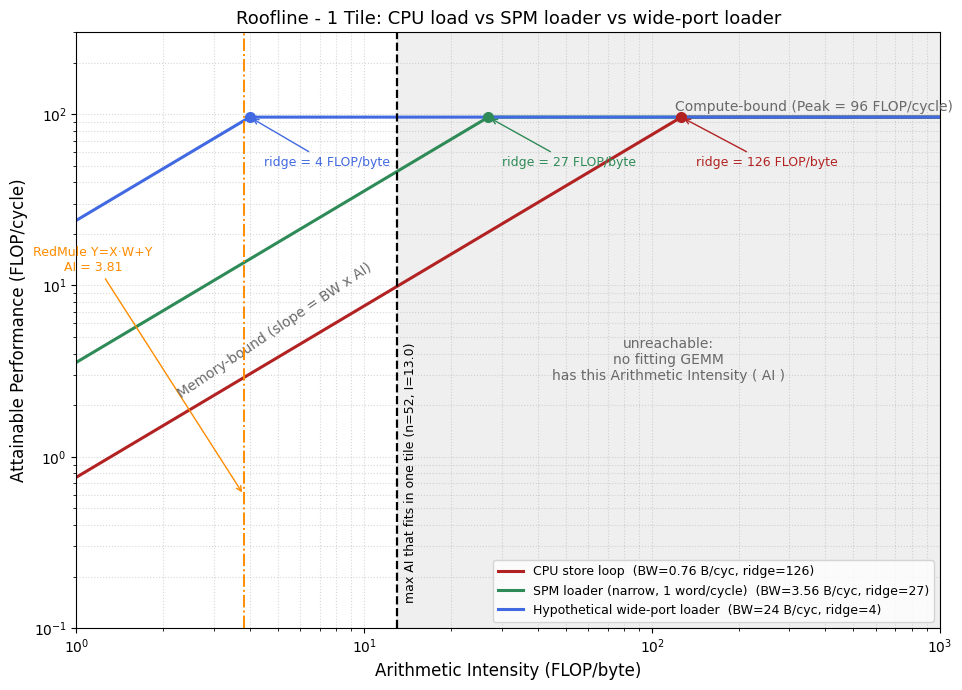

In [7]:

%matplotlib inline
import numpy as np
# import matplotlib
# matplotlib.use("Agg")          # headless backend so the script runs without a display
import matplotlib.pyplot as plt


# ----------------------------------------------------------------------------
# Shared / machine constants
# ----------------------------------------------------------------------------
PEAK = 96.0            # FLOP/cycle, flat compute roof: 48 FMA units x 2 FLOP/unit/cycle (FP16)
BYTES_PER_ELEM = 2     # FP16 = 2 bytes/element
HCI_DW = 288 # see vendor/redmule/rtl/redmule_pkg.sv
N_TCDM_BANKS = HCI_DW // 32
SPM_ROWS = 512 # see vendor/isolde-soc/rtl/cluster/isolde_tile.sv
SPM_BYTES = (N_TCDM_BANKS-1) * SPM_ROWS * 4
DMEM_PORT_BYTES = 4    # 32-bit data memory word (one word/cycle ceiling for the narrow path)
ENGINE_PORT_BYTES = 36 # engine's own scratchpad port width (288-bit), for reference annotation

# Clearly-labeled assumption: the wide-port loader bandwidth (bytes/cycle).
# 24 bytes/cycle == 6 DMEM words/cycle, an illustrative "wide" value roughly
# approaching the engine side. Change this to explore other wide-port designs.
WIDE_BW = 24.0         # bytes/cycle (ASSUMPTION -- edit to taste)


# ----------------------------------------------------------------------------
# The three operand-delivery scenarios
# ----------------------------------------------------------------------------
scenarios = [
    {"name": "CPU store loop",                      "bw": 0.76,    "color": "firebrick"},
    {"name": "SPM loader (narrow, 1 word/cycle)",   "bw": 3.56,    "color": "seagreen"},
    {"name": "Hypothetical wide-port loader",       "bw": WIDE_BW, "color": "royalblue"},
]


# ----------------------------------------------------------------------------
# Feasibility: largest square GEMM order n that fits in one tile's SPM.
#
#   Three n x n FP16 matrices (A, B, C) must fit in SPM_BYTES:
#       3 * n^2 * BYTES_PER_ELEM <= SPM_BYTES
#   =>  n_max = floor( sqrt( SPM_BYTES / (3 * BYTES_PER_ELEM) ) )
#
# Arithmetic intensity of a square GEMM of order n:
#       FLOP  = 2 * n^3
#       bytes = 4 * n^2 * BYTES_PER_ELEM = 8 * n^2   (with BYTES_PER_ELEM = 2)
#       I     = FLOP / bytes = 2 n^3 / 8 n^2 = n / 4
# ----------------------------------------------------------------------------
n_max = int(np.floor(np.sqrt(SPM_BYTES / (3 * BYTES_PER_ELEM))))
I_max = n_max / 4.0
# ----------------------------------------------------------------------------
# RedMule operating point: Y = X*W + Y   (X:12x16, W:16x16, Y:12x16)
# ----------------------------------------------------------------------------
M, K, N = 12, 16, 16
flop  = 2 * M * K * N + M * N                       # GEMM + accumulate  = 6336
byte  = (M*K + K*N + M*N + M*N) * BYTES_PER_ELEM    # read X,W,Y + write Y = 1664
redmule_i = flop / byte                             # ~3.81 FLOP/byte


# ----------------------------------------------------------------------------
# Build the figure
# ----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 7))

# Arithmetic-intensity sweep for the roofline curves.
ai = np.logspace(0, 3, 600)    # 1 .. 1000 FLOP/byte

ridges = {}
ax.axvline(redmule_i, color="darkorange", ls="-.", lw=1.4, zorder=4)
ax.annotate(f"RedMule Y=X·W+Y\nAI = {redmule_i:.2f}",
            xy=(redmule_i, 0.6), xytext=(redmule_i * 0.30, 0.6),
            textcoords=ax.get_xaxis_transform(),
            fontsize=9, color="darkorange", ha="center",
            arrowprops=dict(arrowstyle="->", color="darkorange", lw=1))
for s in scenarios:
    bw   = s["bw"]
    name = s["name"]
    col  = s["color"]

    ridge = PEAK / bw                       # AI where sloped roof meets flat roof
    ridges[name] = ridge

    # performance(I) = min(PEAK, BW * I): sloped part then flat part, one line.
    perf = np.minimum(PEAK, bw * ai)
    ax.plot(ai, perf, color=col, lw=2.2,
            label=f"{name}  (BW={bw:g} B/cyc, ridge={ridge:.0f})")

    # Mark and annotate the ridge point.
    ax.plot(ridge, PEAK, "o", color=col, ms=7, zorder=5)
    ax.annotate(f"ridge = {ridge:.0f} FLOP/byte",
                xy=(ridge, PEAK), xytext=(ridge * 1.12, PEAK * 0.52),
                color=col, fontsize=9,
                arrowprops=dict(arrowstyle="->", color=col, lw=1))

# ----------------------------------------------------------------------------
# Feasibility overlay
# ----------------------------------------------------------------------------
# Vertical dashed line at the max AI that fits in one tile.
ax.axvline(I_max, color="black", ls="--", lw=1.6)
ax.annotate(f"max AI that fits in one tile (n={n_max}, I={I_max:.1f})",
            xy=(I_max, 0.2), xytext=(I_max * 1.06, 0.14),
            rotation=90, va="bottom", ha="left", fontsize=9, color="black")

# # Lightly shade the region to the RIGHT of I_max (unreachable by any fitting GEMM).
# ax.axvspan(I_max, ai[-1], color="gray", alpha=0.12, zorder=0)
# ax.annotate("unreachable:\nno fitting GEMM\nhas this AI",
#             xy=(I_max * 3.2, 0.3), fontsize=9, color="dimgray",
#             ha="center", va="center")
# Lightly shade the region to the RIGHT of I_max (unreachable by any fitting GEMM).
ax.axvspan(I_max, ai[-1], color="gray", alpha=0.12, zorder=0)

# Center the label in the shaded band. Both axes are log scale,
# so the visual midpoint is the geometric mean of the two edges.
x_mid = np.sqrt(I_max * ai[-1])            # ~132 for I_max = 17.3 and x_max = 1000
ax.text(x_mid, 0.45, "unreachable:\nno fitting GEMM\nhas this Arithmetic Intensity ( AI )",
        transform=ax.get_xaxis_transform(),   # x in data units, y as a fraction of the axes height
        fontsize=10, color="dimgray", ha="center", va="center")
# ----------------------------------------------------------------------------
# Regime annotations (once)
# ----------------------------------------------------------------------------
ax.annotate("Memory-bound (slope = BW x AI)",
            xy=(2.2, 2.2), rotation=34, fontsize=10, color="dimgray")
ax.annotate("Compute-bound (Peak = 96 FLOP/cycle)",
            xy=(120, PEAK * 1.08), fontsize=10, color="dimgray")

# Reference note on the engine port width.
# ax.text(0.98, 0.02,
#         f"engine port = {ENGINE_PORT_BYTES} B/cyc (288-bit), "
#         f"DMEM word = {DMEM_PORT_BYTES} B",
#         transform=ax.transAxes, ha="right", va="bottom",
#         fontsize=8, color="gray")

# ----------------------------------------------------------------------------
# Axes cosmetics
# ----------------------------------------------------------------------------
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1, 1000)
ax.set_ylim(0.1, 300)
ax.set_xlabel("Arithmetic Intensity (FLOP/byte)", fontsize=12)
ax.set_ylabel("Attainable Performance (FLOP/cycle)", fontsize=12)
ax.set_title("Roofline - 1 Tile: CPU load vs SPM loader vs wide-port loader",
             fontsize=13)
ax.grid(True, which="both", ls=":", alpha=0.5)   # major + minor on log axes
ax.legend(loc="lower right", fontsize=9)

fig.tight_layout()
plt.show()

In [ ]:

from pathlib import Path

# ----------------------------------------------------------------------------
# Save (create the output folder if needed)
# ----------------------------------------------------------------------------
OUT_PNG = Path("fig/roofline_three_scenarios.png")   # relative to the notebook's folder
OUT_PNG.parent.mkdir(parents=True, exist_ok=True)    # makes fig/ if it's missing, no error if it exists
fig.savefig(OUT_PNG, dpi=150, bbox_inches="tight")

# ----------------------------------------------------------------------------
# Confirmation
# ----------------------------------------------------------------------------
print(f"Wrote: {OUT_PNG.resolve()}")
print(f"n_max = {n_max}  (I_max = {I_max:.1f} FLOP/byte)")
for name, r in ridges.items():
    print(f"  ridge[{name}] = {r:.1f} FLOP/byte")



